In [10]:
# imports
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

# load data
d = sio.loadmat('/Users/diyasajlar/sense-cgsense/data/kneePD.mat')
ksp = np.transpose(d['kspace'], (1, 2, 0))
S = np.transpose(d['coils'], (1, 2, 0))
nx, ny, nc = ksp.shape

# fft2c and ifft2c (fourier transform and inverse fourier transform)
def fft2c(x):
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(x, axes=(0,1)), axes=(0,1), norm='ortho'), axes=(0,1))
def ifft2c(x):
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(x, axes=(0,1)), axes=(0,1), norm='ortho'), axes=(0,1))

coil_imgs = ifft2c(ksp)



0.97268534 0.0001090161
1.0


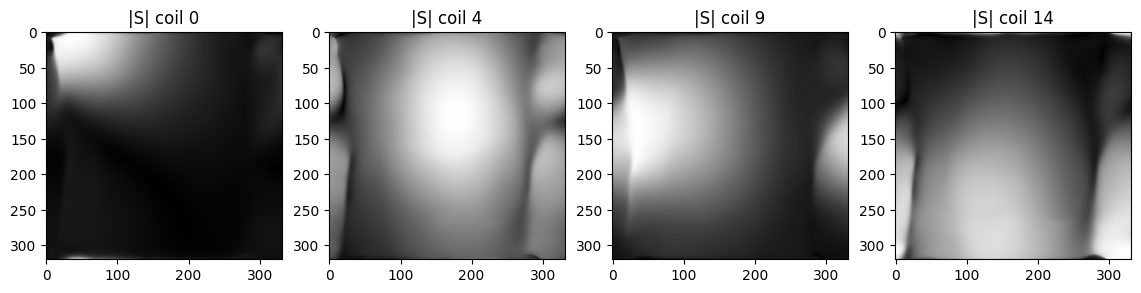

In [11]:
# sensitivity maps
print(np.abs(S).max(), np.abs(S).min())
print(np.sum(np.abs(S)**2, axis=2).mean())   # ~1 if normalized sensitivities
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for i, c in enumerate([0, 4, 9, 14]):
    ax[i].imshow(np.abs(S[:, :, c]), cmap='gray'); ax[i].set_title(f'|S| coil {c}')
plt.show()

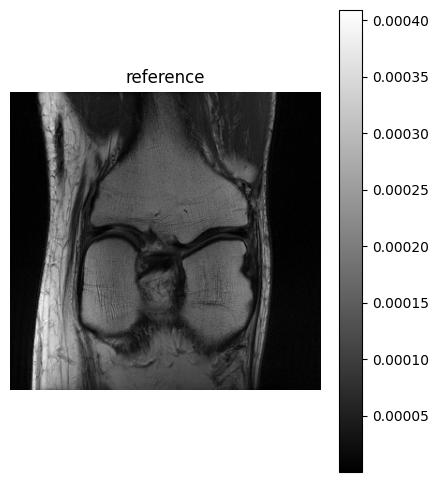

In [12]:
# least-squares coil combination: finds rho such that coil_imgs ≈ S * rho
ref = np.sum(np.conj(S) * coil_imgs, axis=2) / (np.sum(np.abs(S)**2, axis=2) + 1e-8)

plt.figure(figsize=(5, 6))
plt.imshow(np.abs(ref), cmap='gray'); plt.title('reference'); plt.colorbar()
plt.axis('off')
plt.show()

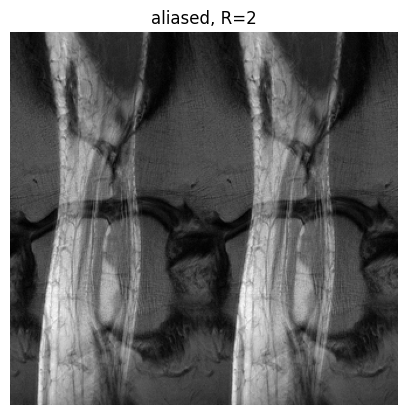

In [13]:
# folding aliasing
R = 2
ky = np.arange(ny) - ny//2
mask = (ky % R == 0).astype(float)[None, :, None]   # keeps every R-th line along axis 1
ksp_us = ksp * mask
alias = ifft2c(ksp_us)

plt.figure(figsize=(5, 6))
plt.imshow(np.sqrt(np.sum(np.abs(alias)**2, axis=2)), cmap='gray')
plt.title(f'aliased, R={R}')
plt.axis('off')
plt.show()

In [14]:
# SENSE unfolding
def sense_unfold(alias, S, R, lam=1e-6):
    nx, ny, nc = S.shape
    nyr = ny // R
    Sm = S.reshape(nx, R, nyr, nc).transpose(0, 2, 3, 1)        # (nx, nyr, nc, R)
    a  = R * alias[:, :nyr, :]                                   # undo the 1/R scaling
    A  = np.einsum('xycr,xycs->xyrs', Sm.conj(), Sm)             # S^H S
    rhs = np.einsum('xycr,xyc->xyr', Sm.conj(), a)               # S^H a
    eps = lam * np.max(np.trace(A, axis1=2, axis2=3).real) / R   # regularize empty pixels
    Areg = A + eps * np.eye(R)
    v = np.linalg.solve(Areg, rhs[..., None])[..., 0]            # (nx, nyr, R)
    Ainv = np.linalg.inv(Areg)
    g = np.sqrt(np.abs(np.einsum('xyrr->xyr', Ainv) * np.einsum('xyrr->xyr', A)))
    rho = v.transpose(0, 2, 1).reshape(nx, ny)
    g   = g.transpose(0, 2, 1).reshape(nx, ny)
    return rho, g

In [15]:
# SENSE NRMSE
rho, g = sense_unfold(alias, S, R)

# normalized root mean square error
def nrmse(a, b):
    return np.linalg.norm(np.abs(a) - np.abs(b)) / np.linalg.norm(np.abs(b))

# Test A: simulate aliased data directly from the model, then unfold it
alias_sim = ifft2c(fft2c(S * ref[..., None]) * mask)
rho_test, _ = sense_unfold(alias_sim, S, R)
print('synthetic NRMSE:', nrmse(rho_test, ref))   # should be tiny (~1e-3 or less)

# Test B: the real data
print('real-data NRMSE:', nrmse(rho, ref))

synthetic NRMSE: 1.4328249432424842e-06
real-data NRMSE: 0.034865703797357844


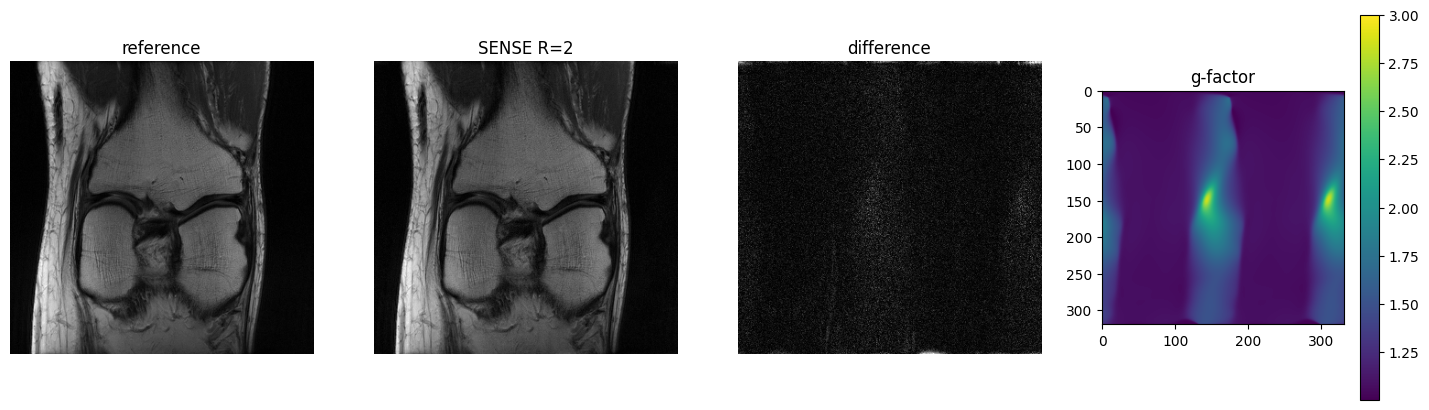

In [16]:
# plot generation (left to right: reference, SENSE, difference, g-factor)
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].axis('off')
ax[0].imshow(np.abs(ref), cmap='gray');  ax[0].set_title('reference')
ax[1].axis('off')
ax[1].imshow(np.abs(rho), cmap='gray');  ax[1].set_title(f'SENSE R={R}')
ax[2].axis('off')
ax[2].imshow(np.abs(np.abs(rho) - np.abs(ref)), cmap='gray'); ax[2].set_title('difference')
im = ax[3].imshow(g, cmap='viridis', vmax=3); ax[3].set_title('g-factor')
fig.colorbar(im, ax=ax[3])
plt.show()

In [17]:
# use double precision so the adjoint test is clean (complex64)
ksp_d = ksp.astype(np.complex128)
S_d = S.astype(np.complex128)

def make_ops(R):
    ky = np.arange(ny) - ny//2
    mask = (ky % R == 0).astype(float)[None, :, None]   #(1, ny, 1) -> keeps every R-th line along axis 1
    
    def E(x):                                           # (nx, ny) -> (nx, ny, nc)
        return mask * fft2c(S_d * x[..., None])
    
    def EH(y):                                          # (nx, ny, nc) -> (nx, ny)
        return np.sum(np.conj(S_d) * ifft2c(mask * y), axis=2)

    return E, EH, mask

In [18]:
# adjoint test
E, EH, mask = make_ops(2)
x = np.random.randn(nx, ny) + 1j*np.random.randn(nx, ny)
y = np.random.randn(nx, ny, nc) + 1j*np.random.randn(nx, ny, nc)
lhs = np.vdot(E(x), y)        # vdot conjugates its first argument
rhs = np.vdot(x, EH(y))
print(lhs, rhs, abs(lhs - rhs) / abs(lhs))   # relative difference should be ~1e-15

(-311.8688771341725+147.6094933291679j) (-311.868877134165+147.6094933291674j) 2.1791473338340635e-14


In [19]:
def cg_sense(E, EH, m, maxit=50, tol=1e-6, ref=None):
    A = lambda x: EH(E(x))                 # the matrix we invert, as a function
    b = EH(m)                              # right-hand side ("a" in the paper)
    v = np.zeros_like(b)                   # start from zero, as the paper recommends
    r = b.copy()                           # residual b - A v, with v = 0
    p = r.copy()                           # first search direction
    rs = np.vdot(r, r).real
    bnorm = np.sqrt(np.vdot(b, b).real)
    hist = {'delta': [], 'err': []}
    for i in range(maxit):
        q = A(p)
        alpha = rs / np.vdot(p, q).real    # step length
        v = v + alpha * p
        r = r - alpha * q
        rs_new = np.vdot(r, r).real
        hist['delta'].append(np.sqrt(rs_new) / bnorm)         # the paper's delta
        if ref is not None:
            hist['err'].append(nrmse(v, ref))                  # true error vs reference
        if hist['delta'][-1] < tol:
            break
        p = r + (rs_new / rs) * p          # new direction, conjugate to the old ones
        rs = rs_new
    return v, hist

In [20]:
R = 2
E, EH, mask = make_ops(R)
m = ksp_d * mask                                   # undersampled data
v2, hist2 = cg_sense(E, EH, m, maxit=50, tol=1e-6, ref=ref)

rho_s, g_s = run_sense(R)                          # SENSE result
print('iterations:', len(hist2['delta']))
print('CG-SENSE vs reference NRMSE:', nrmse(v2, ref))
print('SENSE    vs reference NRMSE:', nrmse(rho_s, ref))
print('CG-SENSE vs SENSE NRMSE:    ', nrmse(v2, rho_s))   # big check

NameError: name 'run_sense' is not defined

R=2: iters=42, CG NRMSE=0.0349, SENSE NRMSE=0.0349, CG vs SENSE=1.47e-06
R=4: iters=100, CG NRMSE=0.3220, SENSE NRMSE=0.3261, CG vs SENSE=2.35e-02


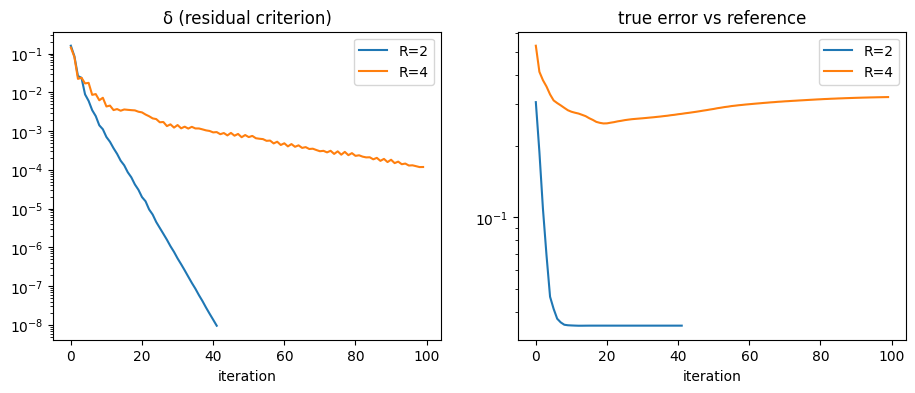

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for R_ in [2, 4]:
    E_, EH_, mask_ = make_ops(R_)
    v_, h_ = cg_sense(E_, EH_, ksp_d * mask_, maxit=100, tol=1e-8, ref=ref)
    ax[0].semilogy(h_['delta'], label=f'R={R_}')
    ax[1].semilogy(h_['err'],   label=f'R={R_}')
    rho_s_, _ = run_sense(R_)
    print(f'R={R_}: iters={len(h_["delta"])}, CG NRMSE={nrmse(v_, ref):.4f}, '
          f'SENSE NRMSE={nrmse(rho_s_, ref):.4f}, CG vs SENSE={nrmse(v_, rho_s_):.2e}')
ax[0].set_title('δ (residual criterion)'); ax[1].set_title('true error vs reference')
for a in ax: a.set_xlabel('iteration'); a.legend()
plt.show()

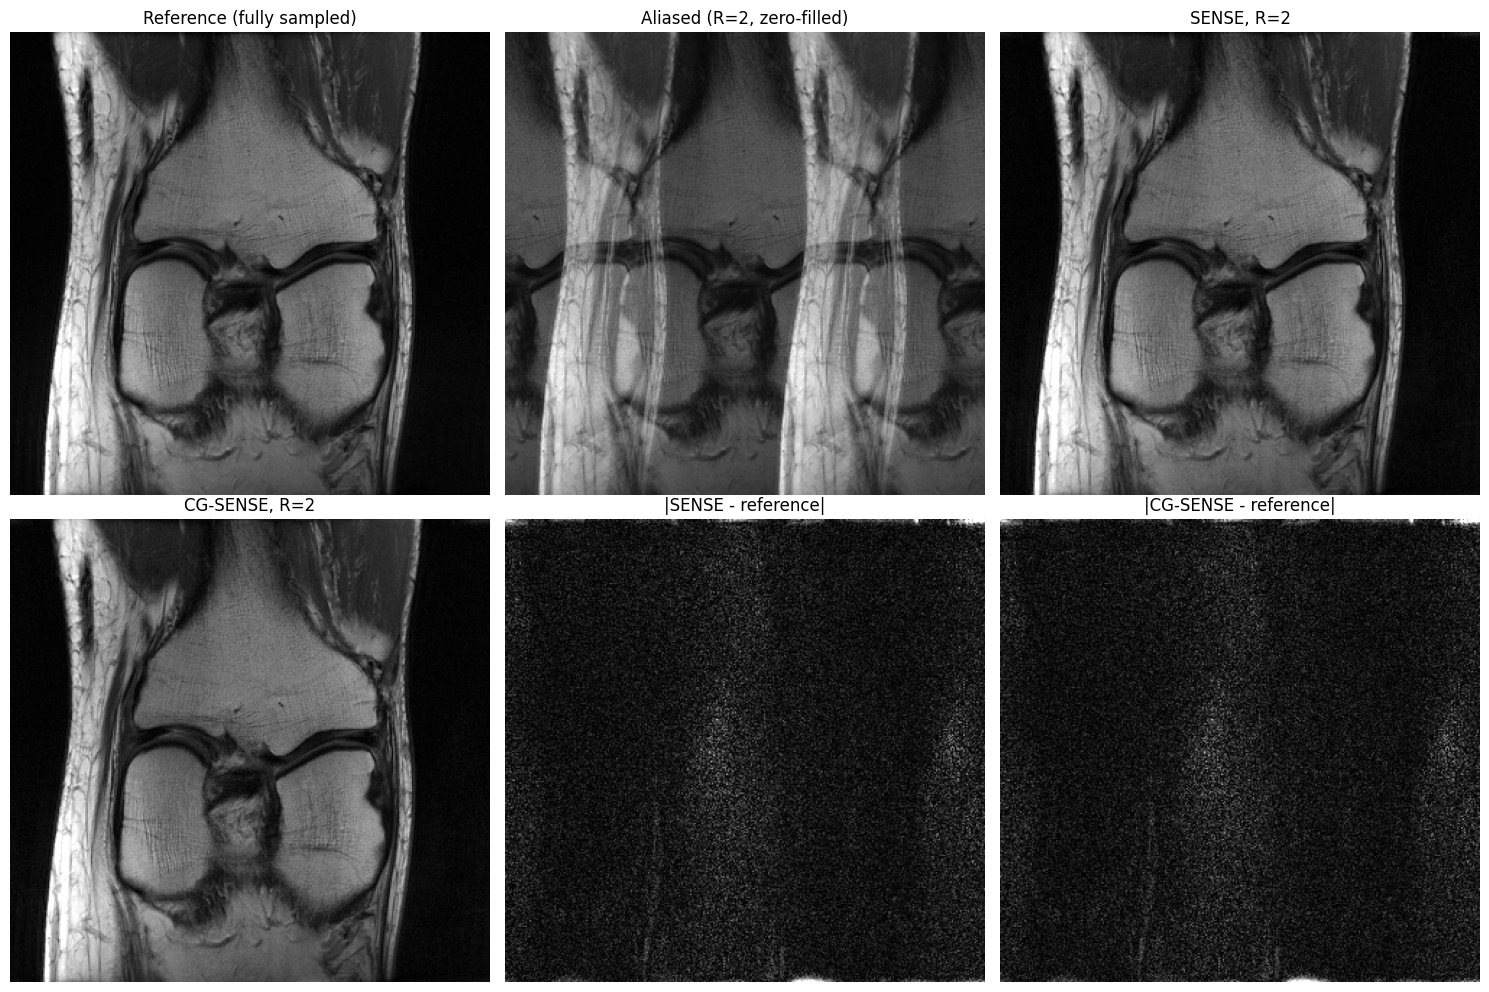

In [ ]:
mask2 = make_ops(2)[2]
alias_rss = np.sqrt(np.sum(np.abs(ifft2c(ksp * mask2))**2, axis=2))

vmax = np.percentile(np.abs(ref), 99.5)         # shared brightness scale for every image
dmax = 0.1 * vmax                               # shared (zoomed-in) scale for difference images

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
panels = [
    (np.abs(ref),                'Reference (fully sampled)', vmax),
    (alias_rss,                  'Aliased (R=2, zero-filled)', None),
    (np.abs(rho_s),              'SENSE, R=2', vmax),
    (np.abs(v2),                 'CG-SENSE, R=2', vmax),
    (np.abs(np.abs(rho_s) - np.abs(ref)), '|SENSE - reference|', dmax),
    (np.abs(np.abs(v2) - np.abs(ref)),    '|CG-SENSE - reference|', dmax),
]
for a, (img, title, vm) in zip(ax.flat, panels):
    im = a.imshow(img, cmap='gray', vmin=0, vmax=vm)
    a.set_title(title); a.axis('off')
plt.tight_layout(); plt.show()

R=2: iters=30  CG NRMSE=0.0349  SENSE NRMSE=0.0349  CG vs SENSE=4.35e-06
R=4: iters=100  CG NRMSE=0.3220  SENSE NRMSE=0.3261  CG vs SENSE=2.35e-02


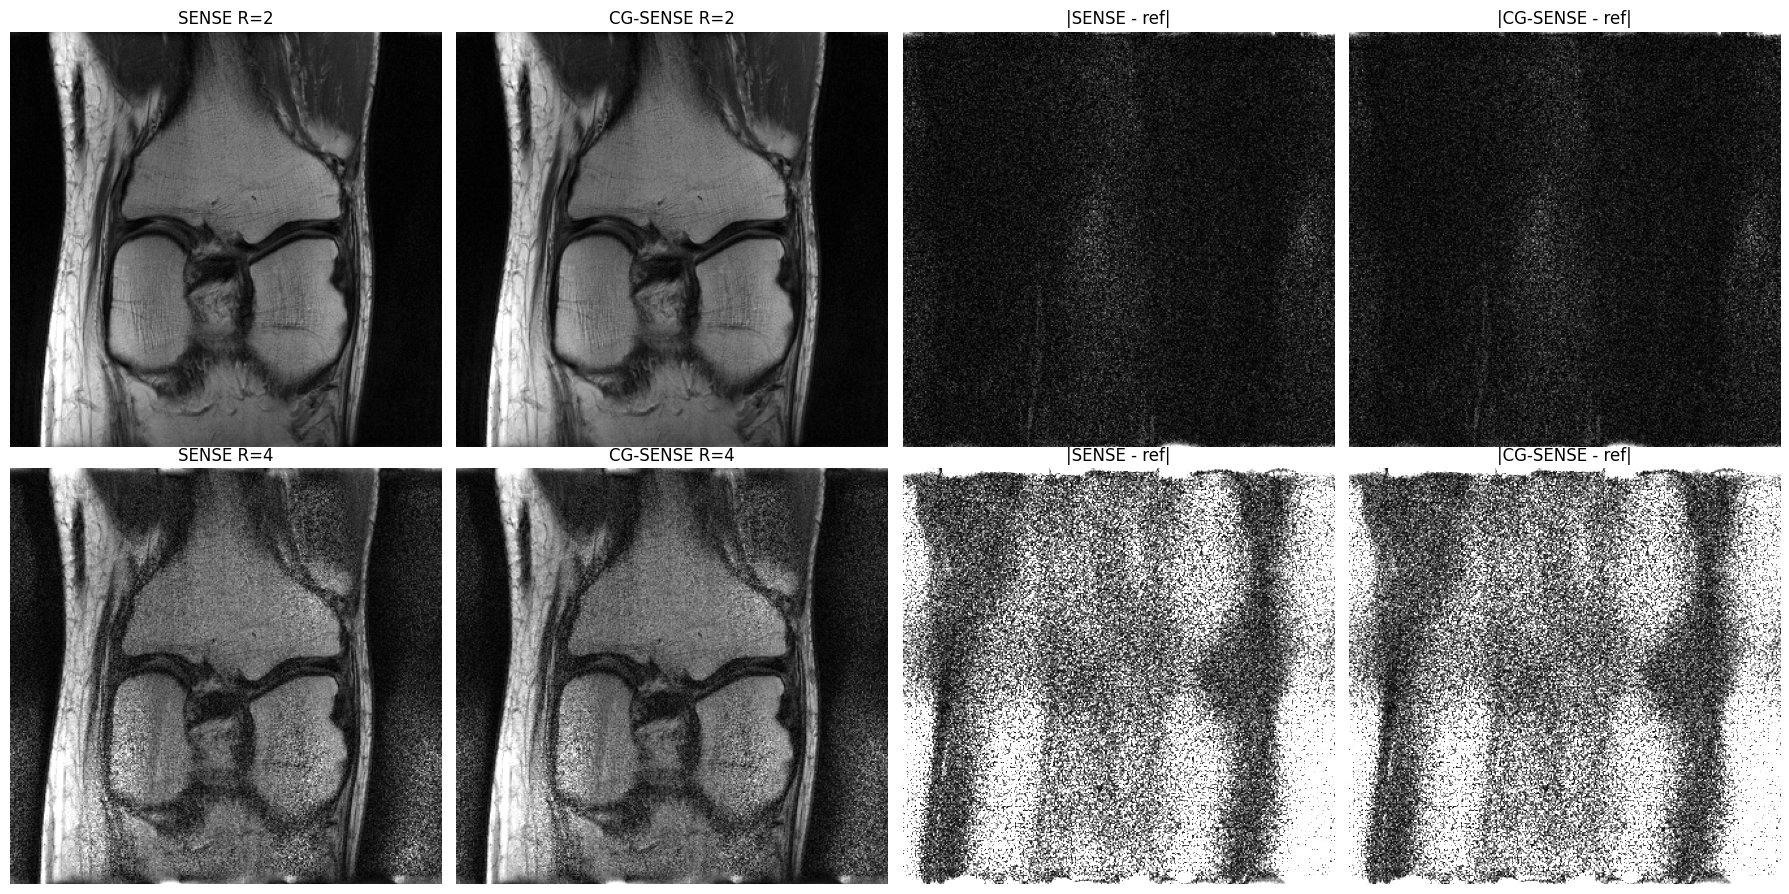

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for i, R_ in enumerate([2, 4]):
    E_, EH_, mask_ = make_ops(R_)
    v_, h_ = cg_sense(E_, EH_, ksp_d * mask_, maxit=100, tol=1e-6, ref=ref)
    rho_, _ = run_sense(R_)
    print(f'R={R_}: iters={len(h_["delta"])}  CG NRMSE={nrmse(v_, ref):.4f}  '
          f'SENSE NRMSE={nrmse(rho_, ref):.4f}  CG vs SENSE={nrmse(v_, rho_):.2e}')
    ax[i, 0].imshow(np.abs(rho_), cmap='gray', vmin=0, vmax=vmax); ax[i, 0].set_title(f'SENSE R={R_}')
    ax[i, 1].imshow(np.abs(v_),   cmap='gray', vmin=0, vmax=vmax); ax[i, 1].set_title(f'CG-SENSE R={R_}')
    ax[i, 2].imshow(np.abs(np.abs(rho_) - np.abs(ref)), cmap='gray', vmin=0, vmax=dmax); ax[i, 2].set_title('|SENSE - ref|')
    ax[i, 3].imshow(np.abs(np.abs(v_) - np.abs(ref)),   cmap='gray', vmin=0, vmax=dmax); ax[i, 3].set_title('|CG-SENSE - ref|')
for a in ax.flat: a.axis('off')
plt.tight_layout(); plt.show()

In [21]:
# SENSE SSIM
ref = np.sum(np.conj(S) * coil_imgs, axis=2) / (np.sum(np.abs(S)**2, axis=2) + 1e-8)

def run_sense(R):
    ky = np.arange(ny) - ny//2
    mask = (ky % R == 0).astype(float)[None, :, None]   # keep every R-th line
    alias = ifft2c(ksp * mask)                           # aliased coil images
    rho, g = sense_unfold(alias, S, R)
    return rho, g

from skimage.metrics import structural_similarity as ssim

obj = np.abs(ref) > 0.1 * np.abs(ref).max()         # rough knee mask
dr  = np.abs(ref).max() - np.abs(ref).min()         # same data range for every score

def ssim_scores(img, ref):
    s_all, smap = ssim(np.abs(ref), np.abs(img), data_range=dr, full=True)
    return s_all, smap[obj].mean(), smap

recons, ssim_maps = {}, {}
print(f'{"":<14}{"SSIM (all)":>12}{"SSIM (knee)":>13}{"NRMSE":>9}{"iters":>7}')
for R_ in [2, 4]:
    # SENSE
    rho_, _ = run_sense(R_)
    sa, so, sm = ssim_scores(rho_, ref)
    recons[('SENSE', R_)], ssim_maps[('SENSE', R_)] = rho_, sm
    print(f'{"SENSE R="+str(R_):<14}{sa:>12.4f}{so:>13.4f}{nrmse(rho_, ref):>9.4f}{"-":>7}')

    # CG-SENSE
    E_, EH_, mask_ = make_ops(R_)
    v_, h_ = cg_sense(E_, EH_, ksp_d * mask_, maxit=100, tol=1e-6, ref=ref)
    sa, so, sm = ssim_scores(v_, ref)
    recons[('CG', R_)], ssim_maps[('CG', R_)] = v_, sm
    print(f'{"CG-SENSE R="+str(R_):<14}{sa:>12.4f}{so:>13.4f}{nrmse(v_, ref):>9.4f}{len(h_["delta"]):>7}')


                SSIM (all)  SSIM (knee)    NRMSE  iters
SENSE R=2           0.9546       0.9737   0.0349      -
CG-SENSE R=2        0.9546       0.9737   0.0349     30
SENSE R=4           0.4616       0.5366   0.3261      -
CG-SENSE R=4        0.4624       0.5377   0.3220    100


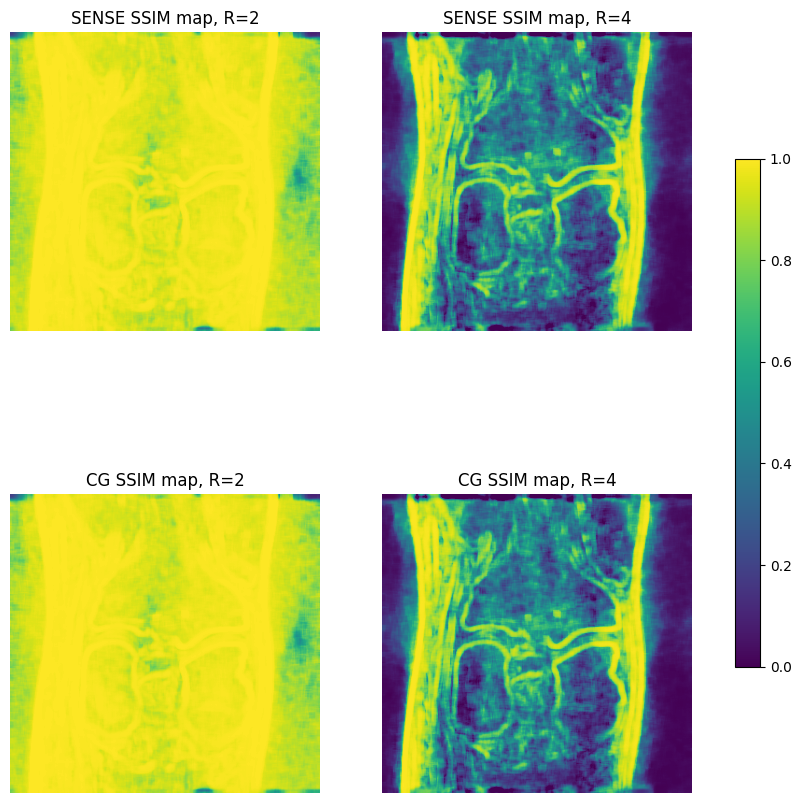

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
for j, R_ in enumerate([2, 4]):
    for i, name in enumerate(['SENSE', 'CG']):
        im = ax[i, j].imshow(ssim_maps[(name, R_)], cmap='viridis', vmin=0, vmax=1)
        ax[i, j].set_title(f'{name} SSIM map, R={R_}')
        ax[i, j].axis('off')
fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()